=== Struktur dan Tipe Data ===
<class 'pandas.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     str    
 1   Nama           99 non-null     str    
 2   Jenis_Kelamin  99 non-null     str    
 3   Prodi          99 non-null     str    
 4   Status         99 non-null     str    
 5   Nilai_Akhir    70 non-null     str    
 6   Tanggal_Ujian  99 non-null     str    
 7   Umur           90 non-null     float64
dtypes: float64(1), str(7)
memory usage: 10.8 KB

=== Jumlah Nilai Hilang (Missing Values) ===
ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir      29
Tanggal_Ujian     0
Umur              9
dtype: int64

=== Statistik Deskriptif ===
           ID Nama Jenis_Kelamin            Prodi Status Nilai_Akhir  \
count      99   99            99               99     99          70

C:\Users\mbps-arifudin-bast\AppData\Local\Temp\ipykernel_12980\3726241056.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Prodi', palette='viridis')


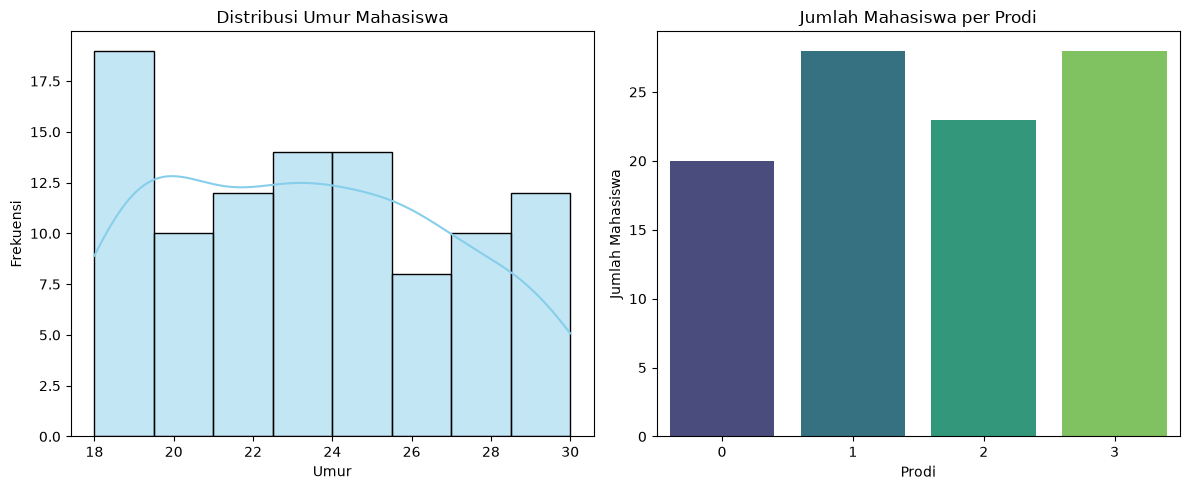

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# ==========================================
# Tahap 1: Load Dataset
# ==========================================
# membaca file dataset
df = pd.read_csv('dataset_tugas1_preprocessing.csv')

# ==========================================
# Tahap 2: Eksplorasi Awal (EDA)
# ==========================================
print("=== Struktur dan Tipe Data ===")
df.info()

print("\n=== Jumlah Nilai Hilang (Missing Values) ===")
print(df.isnull().sum())

print("\n=== Statistik Deskriptif ===")
print(df.describe(include='all'))

# ==========================================
# Tahap 3: Menangani Missing Values
# ==========================================
# Imputasi Umur dengan nilai median (karena bertipe numerik)
if 'Umur' in df.columns:
    df['Umur'] = df['Umur'].fillna(df['Umur'].median())

# Imputasi Nilai_Akhir dengan median (jika numerik) atau modus (jika kategorikal/huruf)
if 'Nilai_Akhir' in df.columns:
    if pd.api.types.is_numeric_dtype(df['Nilai_Akhir']):
        df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(
            df['Nilai_Akhir'].median()
        )
    else:
        df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(
            df['Nilai_Akhir'].mode()[0]
        )

# ==========================================
# Tahap 4: Normalisasi Format Tanggal
# ==========================================
if 'Tanggal_Ujian' in df.columns:
    df['Tanggal_Ujian'] = pd.to_datetime(df['Tanggal_Ujian'], format='mixed')

# ==========================================
# Tahap 5: Encoding Label
# ==========================================
le = LabelEncoder()
kolom_encoding = ['Nama', 'Jenis_Kelamin', 'Prodi', 'Status', 'Nilai_Akhir']

for col in kolom_encoding:
    if col in df.columns:
        # Mengonversi nilai ke string untuk menghindari error tipe campuran
        df[col] = le.fit_transform(df[col].astype(str))

# ==========================================
# Tahap 6: Split Data
# ==========================================
# Memisahkan variabel independen (X) dan dependen (y)
# Contoh asumsi: 'Status' sebagai variabel target (y)
target_column = 'Status' if 'Status' in df.columns else df.columns[-1]

X = df.drop(columns=[target_column])
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\nUkuran Data Latih (X_train): {X_train.shape}")
print(f"Ukuran Data Uji (X_test): {X_test.shape}")

# ==========================================
# Tahap 7: Visualisasi
# ==========================================
plt.figure(figsize=(12, 5))

# 1. Histogram untuk kolom Umur
plt.subplot(1, 2, 1)
sns.histplot(df['Umur'], kde=True, color='skyblue')
plt.title('Distribusi Umur Mahasiswa')
plt.xlabel('Umur')
plt.ylabel('Frekuensi')

# 2. Grafik batang jumlah mahasiswa per Prodi
plt.subplot(1, 2, 2)
sns.countplot(data=df, x='Prodi', palette='viridis')
plt.title('Jumlah Mahasiswa per Prodi')
plt.xlabel('Prodi')
plt.ylabel('Jumlah Mahasiswa')

plt.tight_layout()
plt.show()